# SunSim spec test - PHOENIX mu (new version)

Same run as `SunSim_PHOENIX_mu_test_sophie.ipynb` (O. Porqueras, old SunSim, `compute_forward(observables=['spec'])`), with the new
SunSim: TRAPPIST-1, 5 deg equatorial spot, 32 rings, Phoenix SPECINT models (`models/Phoenix_mu`), 5 epochs over one rotation.
The configuration file and the spot map of the old run are in this folder; the same files are written.

The old run is reproduced with `simulate_old_config(conf, observables=['spec'], spot_map=...)`, which reads the old configuration
file and the old spot map (`read_old_spotmap`) and builds the spectra as the old code:
* spectrum of one cell of every ring = Phoenix SPECINT intensity interpolated at the mu of the ring x projected area / 4 pi
  (linearly to 0 below the smallest tabulated mu); without rotation all the cells of a ring are equal, so one spectrum per ring is kept;
* no Doppler shift and no filter (`convolve_spec_with_filt = False`);
* spot: Phoenix at `temperature_photosphere - spot_T_contrast`; faculae (none here): photosphere x bolometric limb brightening.

**Two runs of the new code**, both compared with the old results:
* `reproduce_old_bugs=False` (default, `results_phoenix_mu_new/`);
* `reproduce_old_bugs=True` (`results_phoenix_mu_new_old_bugs/`).

The mu angles are handled as in the old code in both runs, so both must give the old spectra to rounding precision. The Phoenix
SPECINT models tabulate different mu angles (`lte02500-5.00`: smallest mu 0.00909, `lte02500-5.50`: 0.00685, ...):
* the rows of the 4 models of the T / logg interpolation are added without interpolating them in mu, at the angles of the
  lowest-T, lowest-logg model (`interpolate_phoenix_mu`);
* the old `spec` branch reads the photosphere and then the spot models into the same variable of the angles, so the photosphere
  spectra are interpolated in mu with the angles of the spot model (`lte02300-5.00`: 0.00878, ... instead of 0.00909, ...).

Not reproduced, no effect here: the old spec loop ignores the type of the regions (faculae simulated as spots, wrong `ff_fc`).

**Timings.** The old `compute_forward` reads the models, builds the grids and computes the time series at every call. The new code
does the same in `simulate_old_config` (`first`, `repeat`), but the grids can also be built once and reused for other epochs,
spot maps, inclinations, ...: `reuse grids` is the time of a new `StarSim` with the grids already built (geometry and time series
only), which has no equivalent in the old code.

Old results compared (if the folder exists): `results_phoenix_mu/` (the run of the old notebook; copy its output folder here) and
`results_phoenix_mu_old_local/` (the old StarSim run on this computer by `run_old_starsim_spec.py`).

In [1]:
import os, sys
os.environ.setdefault('KMP_WARNINGS', '0')   # before numpy: silences the OpenMP 'omp_set_nested deprecated' info
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import sunsim
except ImportError:                          # not installed (pip install -e .): the repository, two folders up
    sys.path.insert(0, str(Path.cwd().resolve().parents[1]))
    import sunsim
from sunsim import StarSim, simulate_old_config, read_old_config, read_old_spotmap
from sunsim import local_path   # paths of this computer: local_paths.ini (see local_paths.example.ini)
print('Using:', sunsim.__file__)

# inputs of the old run (this folder), Phoenix SPECINT models, outputs
CONF = 'TRAPPIST1_spec_PHOENIX_mu.conf'
SPOTMAP = 'spotmap.dat'
PHOENIX_MU = local_path('phoenix_models') / 'Phoenix_mu'   # needs 2300-2600 K, logg 5.0-5.5
OLD_RESULTS = ['results_phoenix_mu', 'results_phoenix_mu_old_local']
OUTPUT = {False: 'results_phoenix_mu_new', True: 'results_phoenix_mu_new_old_bugs'}   # by reproduce_old_bugs
N_REUSE = 20                    # repetitions of the timing with the grids reused (the median is kept)

Using: /Users/sophiestucki/sunsim/sunsim/__init__.py


In [2]:
cfg, report = read_old_config(CONF, paths={'phoenix_mu_folder': PHOENIX_MU})
regions = read_old_spotmap(SPOTMAP, config=cfg)
times = np.linspace(0, cfg['rotation_period'], 5, endpoint=False)
print('Times [days]:', times)
print('T_ph = %g K, T_sp = %g K, logg = %g, N_rings = %d, %g-%g A' % (
    cfg['temperature_photosphere'], cfg['temperature_photosphere'] - cfg['spot_T_contrast'], cfg['logg'],
    cfg['n_grid_rings'], cfg['wavelength_lower_limit'], cfg['wavelength_upper_limit']))
for r in regions:
    print('region %s: radius %g deg, colatitude %g deg, longitude %g deg' % (r.type, r.size, r.colatitude, r.longitude))

Times [days]: [0.   0.66 1.32 1.98 2.64]
T_ph = 2566 K, T_sp = 2366 K, logg = 5.2396, N_rings = 32, 4000-25000 A
region sp: radius 5 deg, colatitude 90 deg, longitude 0 deg


## Runs and timings

For each setting: `first` (includes the compilation of the Numba kernels when they are not in the cache, and the first reading of
the Phoenix files, kept in memory afterwards) and `repeat`: the whole `simulate_old_config` (models, grids, time series), as one
call of the old `compute_forward`. Then `reuse grids`: a new `StarSim` with the grids of the previous run (median of `N_REUSE` runs).

In [3]:
def run(reproduce_old_bugs, verbose=False):
    return simulate_old_config(CONF, times=times, observables=['spec'], spot_map=SPOTMAP,
                               paths={'phoenix_mu_folder': PHOENIX_MU}, reproduce_old_bugs=reproduce_old_bugs,
                               verbose=verbose)


def run_reusing_grids(ss):
    """Same simulation with the grids of ss already built: geometry and time series only."""
    new = StarSim(times, ss.N_rings, inclination=ss.inclination, rotation_period=ss.rotation_period,
                  differential_rotation=ss.differential_rotation, stellar_radius=ss.stellar_radius,
                  active_regions_map=ss.active_regions_map, mode=['spectroscopy'],
                  flux_grid_qp=ss.flux_grid_qp, flux_grid_sp=ss.flux_grid_sp, flux_grid_fc=ss.flux_grid_fc)
    new.generate_timeseries(verbose=False)
    return new


results, timings = {}, {}
for bugs in (False, True):
    elapsed = {}
    for label in ['first', 'repeat']:
        start = perf_counter()
        res = run(bugs, verbose=(label == 'first' and not bugs))
        elapsed[label] = perf_counter() - start
    reuse = []
    for _ in range(N_REUSE):
        start = perf_counter()
        again = run_reusing_grids(res['starsim_spec'])
        reuse.append(perf_counter() - start)
    elapsed['reuse grids'] = float(np.median(reuse))
    assert np.array_equal(again.spec_var, res['spec']), 'the grids reused must give the same spectra'
    results[bugs], timings[bugs] = res, elapsed
    print('reproduce_old_bugs=%s: ' % bugs + ', '.join('%s %.3f s' % kv for kv in elapsed.items()))

ss = results[False]['starsim_spec']
print('grid of a surface: %s (one spectrum per ring), %.0f MB' % (ss.flux_grid_qp.shape, ss.flux_grid_qp.nbytes / 1e6))
for t, p, s, f in zip(times, results[False]['ff_ph'], results[False]['ff_sp'], results[False]['ff_fc']):
    print(f'Date {t:.2f}. ff_ph={p:.3f}%. ff_sp={s:.3f}%. ff_fc={f:.3f}%.')

Old configuration TRAPPIST1_spec_PHOENIX_mu.conf (old package .)
  missing keys, default used:
    [general] spectral_library -> 'phoenix' (Phoenix (the only library of the first versions))
    [general] mps_spectra_folder -> 'MPS-ATLAS_spectra' (MPS-ATLAS_spectra of the old package)
    [general] mps_mu_grid -> 0 (Phoenix intensities at their own angles)
    [general] ccf_norm -> 1 (CCF normalised to [0, 1], as in the first versions)
    [general] flux_flat -> 1 (high resolution spectra divided by their continuum, as in the first versions)
    [general] highres_mu -> 1 (mps_highres: spectrum interpolated at the mu of every ring)
    [general] remove_bis_spot -> 1 (MURaM: bisector of the spot CCF removed)
    [general] add_median_diff -> 0.0 (no shift of the spot CCF)
    [rv] instrument -> 'None' (no instrument)
    [LD] limb_extrapolation -> 'linear' (linear: I(mu) = mu / limb_lim * I(limb_lim) below limb_lim)
    [LD] limb_lim -> None (the smallest tabulated mu)
    [LD] meunier -> 

In [4]:
for bugs, folder in OUTPUT.items():
    res = results[bugs]
    output = Path(folder)
    output.mkdir(exist_ok=True)
    pd.DataFrame(res['spec'].T, index=res['spec_wv'],
                 columns=[f'flux_t{t:.6f}_day' for t in times]).rename_axis(
                     'wavelength_A').to_csv(output / 'spectra.csv')
    pd.DataFrame({'time_day': times, **{f'{k}_percent': res[k]
                 for k in ['ff_ph', 'ff_sp', 'ff_fc', 'ff_pl']}}).to_csv(
                     output / 'filling_factors.csv', index=False)
    pd.DataFrame({'call': list(timings[bugs]), 'seconds': list(timings[bugs].values())}).to_csv(
        output / 'timings.csv', index=False)
    np.savez_compressed(output / 'spectra.npz', time=times,
                        spec_wv=res['spec_wv'], spec=res['spec'])
    print('Saved to:', output.resolve())

wavelength = results[False]['spec_wv']     # Angstrom
spectra = results[False]['spec']           # Shape: (time, wavelength), default (bugs corrected)

Saved to: /Users/sophiestucki/sunsim/benchmarks/trappist1_phoenix_mu/results_phoenix_mu_new
Saved to: /Users/sophiestucki/sunsim/benchmarks/trappist1_phoenix_mu/results_phoenix_mu_new_old_bugs


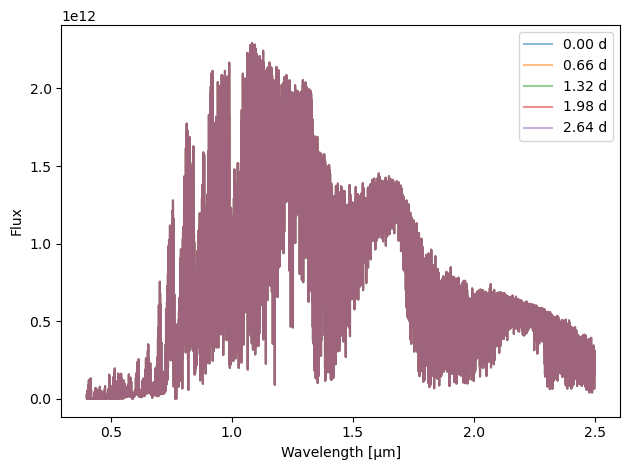

In [5]:
for t, spectrum in zip(times, spectra):
    plt.plot(wavelength / 1e4, spectrum, label=f'{t:.2f} d', alpha=0.5)
plt.xlabel('Wavelength [µm]')
plt.ylabel('Flux')
plt.legend()
plt.tight_layout()
plt.show()

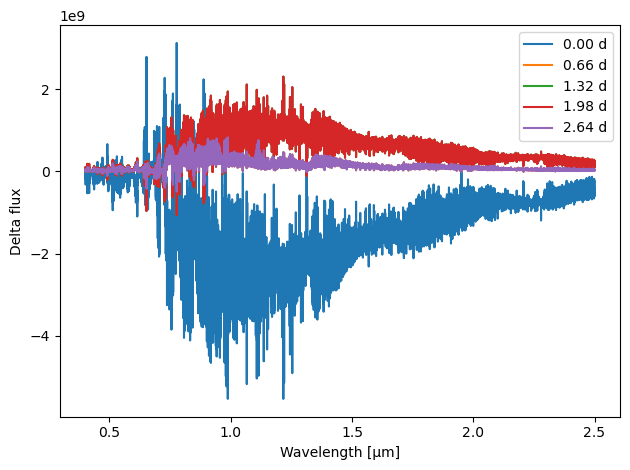

In [6]:
for t, spectrum in zip(times, spectra):
    plt.plot(wavelength / 1e4, spectrum-np.mean(spectra,axis=0), label=f'{t:.2f} d')
plt.xlabel('Wavelength [µm]')
plt.ylabel('Delta flux')
plt.legend()
plt.tight_layout()
plt.show()

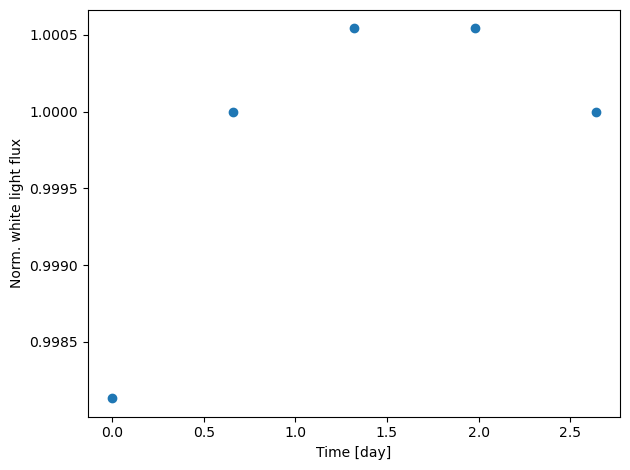

In [7]:
fluxes = np.sum(spectra,axis=1)
fluxes /= np.median(fluxes)
plt.scatter(times, fluxes)
plt.xlabel('Time [day]')
plt.ylabel('Norm. white light flux')
plt.tight_layout()
plt.show()

## Comparison with the old runs

For every folder of `OLD_RESULTS` that exists (`spectra.npz`, `filling_factors.csv`, `timings.csv` of the old notebook): timings,
then the spectra of the two new runs. In both runs the differences must be at the rounding level (~1e-14).

No old results in results_phoenix_mu : skipped
===== results_phoenix_mu_old_local =====
Timings (the old code has no reuse of the grids: every call rebuilds them):
       call  reproduce_old_bugs  old [s]  new [s]  speed-up (old repeat / new)
      first               False    0.947    1.417                        0.182
      first                True    0.947    0.029                        8.789
     repeat               False    0.257    0.044                        5.898
     repeat                True    0.257    0.037                        6.896
reuse grids               False      NaN    0.002                      157.583
reuse grids                True      NaN    0.002                      154.085

--- reproduce_old_bugs=False ---
Filling factors [%], max |new - old|: 1.4e-14
Spectra, new / old - 1: max |.| = 4.00e-15, median |.| = 2.22e-16
White light, new / old - 1: [0. 0. 0. 0. 0.]
Norm. white light variation, new - old: [0. 0. 0. 0. 0.]


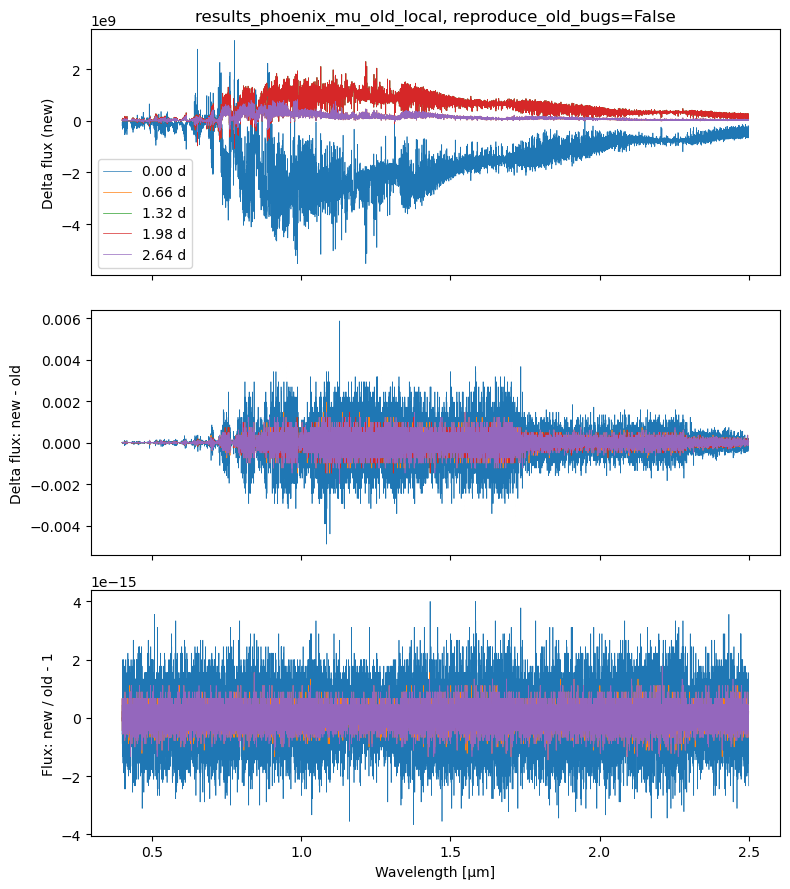


--- reproduce_old_bugs=True ---
Filling factors [%], max |new - old|: 1.4e-14
Spectra, new / old - 1: max |.| = 4.00e-15, median |.| = 2.22e-16
White light, new / old - 1: [0. 0. 0. 0. 0.]
Norm. white light variation, new - old: [0. 0. 0. 0. 0.]


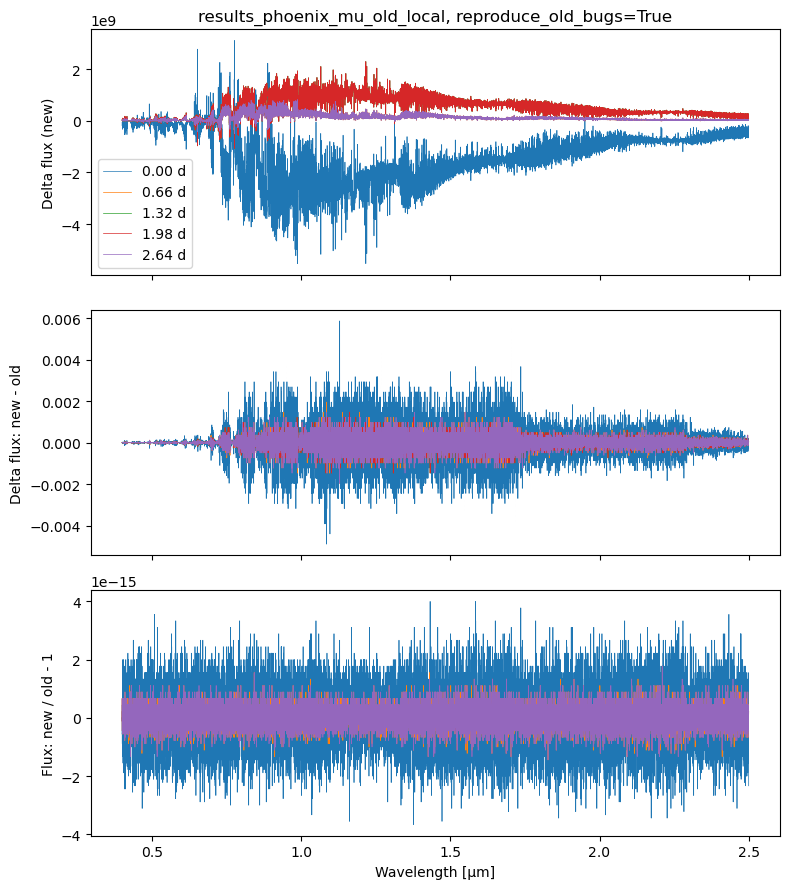

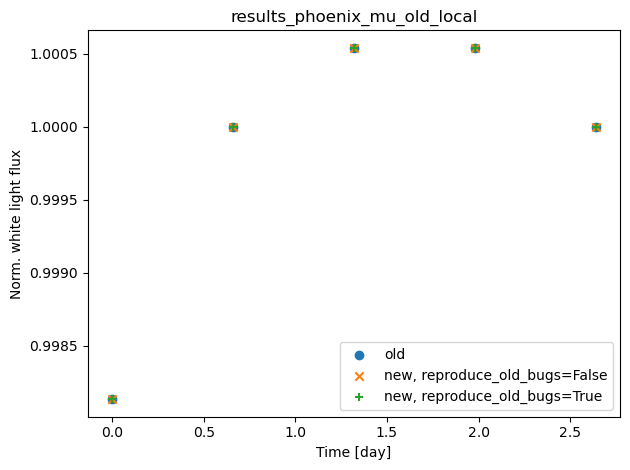

In [8]:
def timing_table(old_time):
    old = dict(zip(old_time['call'], old_time['seconds']))
    rows = []
    for call in ['first', 'repeat', 'reuse grids']:
        o = old.get(call, np.nan)
        for bugs in (False, True):
            n = timings[bugs][call]
            rows.append({'call': call, 'reproduce_old_bugs': bugs, 'old [s]': o, 'new [s]': n,
                         'speed-up (old repeat / new)': old['repeat'] / n})
    return pd.DataFrame(rows)


def compare_spectra(old_dir, old, old_ff, bugs):
    res = results[bugs]
    spec = res['spec']
    assert np.array_equal(old['spec_wv'], res['spec_wv']), 'not the same wavelengths'
    rel = spec / old['spec'] - 1
    print('\n--- reproduce_old_bugs=%s ---' % bugs)
    print('Filling factors [%%], max |new - old|: %.1e' % max(np.max(np.abs(res[k] - old_ff[f'{k}_percent'].values))
                                                            for k in ['ff_ph', 'ff_sp', 'ff_fc', 'ff_pl']))
    print('Spectra, new / old - 1: max |.| = %.2e, median |.| = %.2e' % (np.nanmax(np.abs(rel)), np.nanmedian(np.abs(rel))))
    wl_old = old['spec'].sum(axis=1)
    print('White light, new / old - 1:', spec.sum(axis=1) / wl_old - 1)
    var_old, var_new = wl_old / np.median(wl_old), spec.sum(axis=1) / np.median(spec.sum(axis=1))
    print('Norm. white light variation, new - old:', var_new - var_old)

    fig, axs = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
    for t, s_new, s_old, r in zip(times, spec, old['spec'], rel):
        axs[0].plot(wavelength / 1e4, s_new - spec.mean(axis=0), label=f'{t:.2f} d', lw=0.5)
        axs[1].plot(wavelength / 1e4, (s_new - spec.mean(axis=0)) - (s_old - old['spec'].mean(axis=0)), lw=0.5)
        axs[2].plot(wavelength / 1e4, r, lw=0.5)
    axs[0].set_ylabel('Delta flux (new)'); axs[0].legend()
    axs[1].set_ylabel('Delta flux: new - old')
    axs[2].set_ylabel('Flux: new / old - 1')
    axs[2].set_xlabel('Wavelength [µm]')
    axs[0].set_title('%s, reproduce_old_bugs=%s' % (old_dir, bugs))
    plt.tight_layout()
    plt.show()


def compare(old_dir):
    old = np.load(old_dir / 'spectra.npz')
    old_ff = pd.read_csv(old_dir / 'filling_factors.csv')
    old_time = pd.read_csv(old_dir / 'timings.csv')
    assert np.allclose(old['time'], times), 'not the same epochs'
    print('=====', old_dir, '=====')
    print('Timings (the old code has no reuse of the grids: every call rebuilds them):')
    print(timing_table(old_time).to_string(index=False, float_format='%.3f'))
    for bugs in (False, True):
        compare_spectra(old_dir, old, old_ff, bugs)

    wl_old = old['spec'].sum(axis=1)
    plt.scatter(times, wl_old / np.median(wl_old), label='old')
    for bugs, marker in ((False, 'x'), (True, '+')):
        wl = results[bugs]['spec'].sum(axis=1)
        plt.scatter(times, wl / np.median(wl), marker=marker, label='new, reproduce_old_bugs=%s' % bugs)
    plt.xlabel('Time [day]')
    plt.ylabel('Norm. white light flux')
    plt.title(str(old_dir))
    plt.legend()
    plt.tight_layout()
    plt.show()


for folder in OLD_RESULTS:
    if (Path(folder) / 'spectra.npz').exists():
        compare(Path(folder))
    else:
        print('No old results in', folder, ': skipped')